In [23]:

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

# Preprocessing
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

# Clustering
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import DBSCAN

# Evaluation
from sklearn.metrics import silhouette_score

# Hierarchical clustering
from scipy.cluster.hierarchy import dendrogram, linkage

# Yellowbrick
from yellowbrick.cluster import SilhouetteVisualizer

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)


In [24]:
df = pd.read_csv("ecommerce_customer_segmentation_dataset.csv")

print("Dataset loaded successfully!")
print("Shape of dataset:", df.shape)

Dataset loaded successfully!
Shape of dataset: (10000, 25)


In [25]:
# ============================================
# BASIC DATA UNDERSTANDING
# ============================================

print("Number of Rows    :", df.shape[0])
print("Number of Columns :", df.shape[1])

print("Column Names:")
print(df.columns.tolist())

print("Data Types:")
display(df.dtypes.to_frame("Data_Type"))

print("First 5 Records:")
display(df.head())

Number of Rows    : 10000
Number of Columns : 25
Column Names:
['Customer_ID', 'Age', 'Gender', 'City_Tier', 'Annual_Income', 'Customer_Tenure_Months', 'Total_Orders', 'Total_Spending', 'Average_Order_Value', 'Website_Visits_Per_Month', 'Mobile_App_Usage_Rate', 'Discount_Usage_Rate', 'Cart_Abandonment_Rate', 'Return_Rate', 'Average_Days_Between_Orders', 'Product_Categories_Purchased', 'Electronics_Spending', 'Fashion_Spending', 'Home_Kitchen_Spending', 'Beauty_Spending', 'Customer_Support_Calls', 'Loyalty_Points', 'Last_Purchase_Days_Ago', 'Preferred_Payment_Method', 'Marketing_Response_Rate']
Data Types:


,Data_Type
Customer_ID,object
Age,int64
Gender,object
City_Tier,object
Annual_Income,float64
Customer_Tenure_Months,int64
Total_Orders,int64
Total_Spending,int64
Average_Order_Value,int64
Website_Visits_Per_Month,int64


First 5 Records:


,Customer_ID,Age,Gender,City_Tier,Annual_Income,Customer_Tenure_Months,Total_Orders,Total_Spending,Average_Order_Value,Website_Visits_Per_Month,Mobile_App_Usage_Rate,Discount_Usage_Rate,Cart_Abandonment_Rate,Return_Rate,Average_Days_Between_Orders,Product_Categories_Purchased,Electronics_Spending,Fashion_Spending,Home_Kitchen_Spending,Beauty_Spending,Customer_Support_Calls,Loyalty_Points,Last_Purchase_Days_Ago,Preferred_Payment_Method,Marketing_Response_Rate
0,CUST_00001,18,Male,Tier_3,384000.0,25,2,3900,2100,45,0.83,0.57,0.69,0.08,74.6,3,1800.0,1400.0,300.0,400.0,3,1030,99,UPI,0.34
1,CUST_00002,43,Male,Tier_2,NaN,13,7,19300,2600,9,0.50,0.06,0.57,0.07,109.0,1,3200.0,5100.0,5200.0,5900.0,3,757,24,UPI,0.29
2,CUST_00003,40,Female,Tier_3,1776000.0,54,62,116400,2000,27,0.82,0.42,0.16,0.00,28.5,3,16400.0,75300.0,8700.0,15900.0,3,12229,124,Credit Card,0.39
3,CUST_00004,49,Male,Tier_2,852000.0,10,18,67100,3800,3,0.39,0.51,0.47,0.07,122.5,3,24900.0,19700.0,10700.0,11800.0,1,1454,104,UPI,0.41
4,CUST_00005,28,Female,Tier_2,1339000.0,67,48,318700,5750,37,0.79,0.36,0.16,0.03,11.4,6,123700.0,4300.0,154700.0,35900.0,2,8055,15,UPI,0.36


In [26]:
# ============================================
# STATISTICAL SUMMARY
# ============================================

display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Customer_ID,10000,10000,CUST_00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,10000.0,NaN,NaN,NaN,35.7717,11.279561,18.0,27.0,34.0,43.0,75.0
Gender,10000,3,Female,4900,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City_Tier,10000,3,Tier_1,4262,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Annual_Income,9880.0,NaN,NaN,NaN,874082.489879,441558.283768,150000.0,552000.0,770000.0,1128000.0,2587000.0
Customer_Tenure_Months,10000.0,NaN,NaN,NaN,35.2441,20.841458,1.0,20.0,33.0,49.0,142.0
Total_Orders,10000.0,NaN,NaN,NaN,27.1138,23.443669,1.0,7.0,17.0,46.0,113.0
Total_Spending,10000.0,NaN,NaN,NaN,118971.0922,158352.521189,200.0,12100.0,48100.0,161225.0,1198100.0
Average_Order_Value,10000.0,NaN,NaN,NaN,3388.299,2384.547534,180.0,1550.0,2350.0,5150.0,12150.0
Website_Visits_Per_Month,10000.0,NaN,NaN,NaN,21.9137,25.082826,1.0,8.0,17.0,31.0,472.0


In [27]:
# ============================================
# DUPLICATE CHECK
# ============================================

duplicate_rows = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_rows)

duplicate_customer_ids = df["Customer_ID"].duplicated().sum()

print("Number of duplicate Customer_IDs:", duplicate_customer_ids)

Number of duplicate rows: 0
Number of duplicate Customer_IDs: 0


In [28]:
# ============================================
# MISSING VALUE ANALYSIS
# ============================================

missing_summary = pd.DataFrame({ "Missing_Count": df.isnull().sum(),"Missing_Percentage": (df.isnull().mean() * 100).round(2)})
missing_summary = missing_summary.sort_values("Missing_Count",ascending=False)
display(missing_summary)

,Missing_Count,Missing_Percentage
Annual_Income,120,1.2
Mobile_App_Usage_Rate,80,0.8
Discount_Usage_Rate,60,0.6
Preferred_Payment_Method,40,0.4
Customer_ID,0,0.0
Average_Days_Between_Orders,0,0.0
Last_Purchase_Days_Ago,0,0.0
Loyalty_Points,0,0.0
Customer_Support_Calls,0,0.0
Beauty_Spending,0,0.0


In [29]:
numerical_data.head(1)

,Age,Annual_Income,Customer_Tenure_Months,Total_Orders,Total_Spending,Average_Order_Value,Website_Visits_Per_Month,Mobile_App_Usage_Rate,Discount_Usage_Rate,Cart_Abandonment_Rate,Return_Rate,Average_Days_Between_Orders,Product_Categories_Purchased,Electronics_Spending,Fashion_Spending,Home_Kitchen_Spending,Beauty_Spending,Customer_Support_Calls,Loyalty_Points,Last_Purchase_Days_Ago,Marketing_Response_Rate
0,18,384000.0,25,2,3900,2100,45,0.83,0.57,0.69,0.08,74.6,3,1800.0,1400.0,300.0,400.0,3,1030,99,0.34


In [30]:
# ============================================
# SEPARATE DATA TYPES
# ============================================

# Customer ID
customer_id = df[["Customer_ID"]]
# Categorical columns
categorical_columns = ["Gender","City_Tier","Preferred_Payment_Method"]
categorical_data = df[categorical_columns]
# Numerical data
numerical_data = df.select_dtypes(include=np.number)
print("Numerical data shape:", numerical_data.shape)
print("Categorical data shape:", categorical_data.shape)
print("\nNumerical columns:")
print(numerical_data.columns.tolist())
print("\nCategorical columns:")
print(categorical_data.columns.tolist())

Numerical data shape: (10000, 21)
Categorical data shape: (10000, 3)

Numerical columns:
['Age', 'Annual_Income', 'Customer_Tenure_Months', 'Total_Orders', 'Total_Spending', 'Average_Order_Value', 'Website_Visits_Per_Month', 'Mobile_App_Usage_Rate', 'Discount_Usage_Rate', 'Cart_Abandonment_Rate', 'Return_Rate', 'Average_Days_Between_Orders', 'Product_Categories_Purchased', 'Electronics_Spending', 'Fashion_Spending', 'Home_Kitchen_Spending', 'Beauty_Spending', 'Customer_Support_Calls', 'Loyalty_Points', 'Last_Purchase_Days_Ago', 'Marketing_Response_Rate']

Categorical columns:
['Gender', 'City_Tier', 'Preferred_Payment_Method']


In [31]:
# ============================================
# CLUSTERING FEATURES
#Primary objective is to cluster customers based on purchasing and engagement behavior.
# ============================================

clustering_features = ["Annual_Income","Customer_Tenure_Months","Total_Orders","Total_Spending","Average_Order_Value","Website_Visits_Per_Month",
"Mobile_App_Usage_Rate","Discount_Usage_Rate","Cart_Abandonment_Rate","Return_Rate","Average_Days_Between_Orders","Product_Categories_Purchased",
"Customer_Support_Calls","Loyalty_Points","Last_Purchase_Days_Ago","Marketing_Response_Rate"]

X = df[clustering_features]

print("Number of clustering features:", len(clustering_features))

X.head()

Number of clustering features: 16


,Annual_Income,Customer_Tenure_Months,Total_Orders,Total_Spending,Average_Order_Value,Website_Visits_Per_Month,Mobile_App_Usage_Rate,Discount_Usage_Rate,Cart_Abandonment_Rate,Return_Rate,Average_Days_Between_Orders,Product_Categories_Purchased,Customer_Support_Calls,Loyalty_Points,Last_Purchase_Days_Ago,Marketing_Response_Rate
0,384000.0,25,2,3900,2100,45,0.83,0.57,0.69,0.08,74.6,3,3,1030,99,0.34
1,NaN,13,7,19300,2600,9,0.50,0.06,0.57,0.07,109.0,1,3,757,24,0.29
2,1776000.0,54,62,116400,2000,27,0.82,0.42,0.16,0.00,28.5,3,3,12229,124,0.39
3,852000.0,10,18,67100,3800,3,0.39,0.51,0.47,0.07,122.5,3,1,1454,104,0.41
4,1339000.0,67,48,318700,5750,37,0.79,0.36,0.16,0.03,11.4,6,2,8055,15,0.36


In [32]:
# ============================================
# HANDLE MISSING VALUES (KNN IMPUTATION)
# ============================================

# n_neighbors specifies how many nearest rows to use (default is 5)
imputer = KNNImputer(n_neighbors=5, weights="uniform")

X_imputed = pd.DataFrame(imputer.fit_transform(X),columns=X.columns,index=X.index)

print("Total missing values after imputation:",X_imputed.isnull().sum().sum())

Total missing values after imputation: 0


In [34]:
# ============================================
# FEATURE SCALING
# ============================================

scaler = StandardScaler()

X_scaled = pd.DataFrame(scaler.fit_transform(X_imputed),columns=X_imputed.columns,index=X_imputed.index)

X_scaled.head()

,Annual_Income,Customer_Tenure_Months,Total_Orders,Total_Spending,Average_Order_Value,Website_Visits_Per_Month,Mobile_App_Usage_Rate,Discount_Usage_Rate,Cart_Abandonment_Rate,Return_Rate,Average_Days_Between_Orders,Product_Categories_Purchased,Customer_Support_Calls,Loyalty_Points,Last_Purchase_Days_Ago,Marketing_Response_Rate
0,-1.112570,-0.491550,-1.071294,-0.726713,-0.540297,0.920449,0.807653,0.655147,1.622341,0.067829,0.837887,-0.406964,0.631385,-0.805979,0.379581,-0.267901
1,-1.035400,-1.067354,-0.858006,-0.629457,-0.330603,-0.514868,-0.643249,-1.349677,1.082603,-0.162882,1.802991,-1.517371,0.631385,-0.857983,-0.673914,-0.473447
2,2.046869,0.899977,1.488161,-0.016237,-0.582236,0.202790,0.763687,0.065493,-0.761503,-1.777854,-0.455464,-0.406964,0.631385,1.327328,0.730746,-0.062355
3,-0.050345,-1.211305,-0.388773,-0.327584,0.172662,-0.754088,-1.126883,0.419286,0.632821,-0.162882,2.181738,-0.406964,-0.646981,-0.725210,0.449814,0.019864
4,1.055005,1.523765,0.890955,1.261356,0.990468,0.601489,0.631786,-0.170368,-0.761503,-1.085723,-0.935210,1.258646,-0.007798,0.532219,-0.800333,-0.185682


In [35]:
# ============================================
# K-MEANS FOR DIFFERENT K VALUES
# ============================================

k_values = range(2, 11)

inertia_values = []
silhouette_values = []

for k in k_values:

    kmeans = KMeans( n_clusters=k,random_state=42,n_init=20)
    labels = kmeans.fit_predict(X_scaled)
    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(silhouette_score(X_scaled,labels))

k_results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values,
    "Silhouette_Score": silhouette_values})

k_results

,K,Inertia,Silhouette_Score
0,2,116609.409329,0.283942
1,3,96529.359231,0.239702
2,4,83370.262543,0.256858
3,5,76182.568420,0.255464
4,6,70516.080183,0.233860
5,7,65753.711757,0.238716
6,8,64111.335641,0.203316
7,9,62212.445227,0.191996
8,10,60608.753120,0.163668


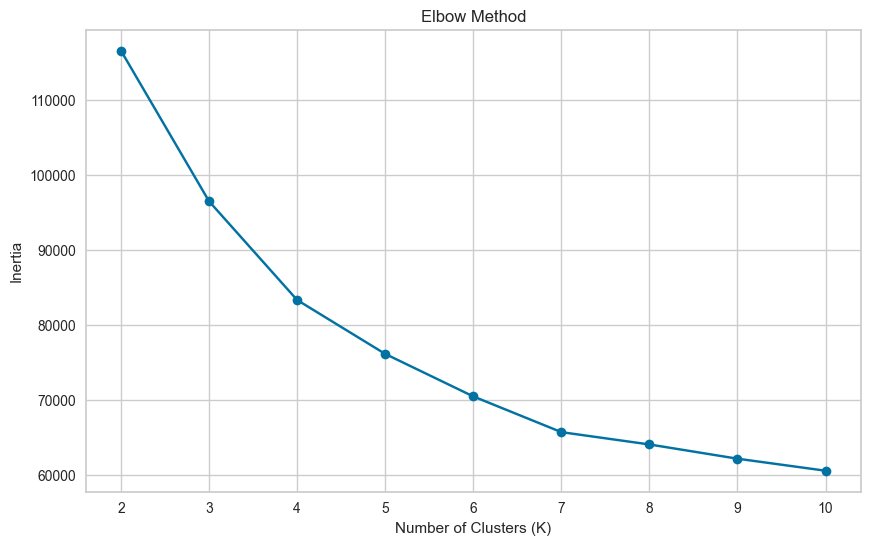

In [36]:
# ============================================
# ELBOW PLOT
# ============================================

plt.figure(figsize=(10, 6))

plt.plot(k_results["K"],k_results["Inertia"],marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(list(k_values))
plt.show()

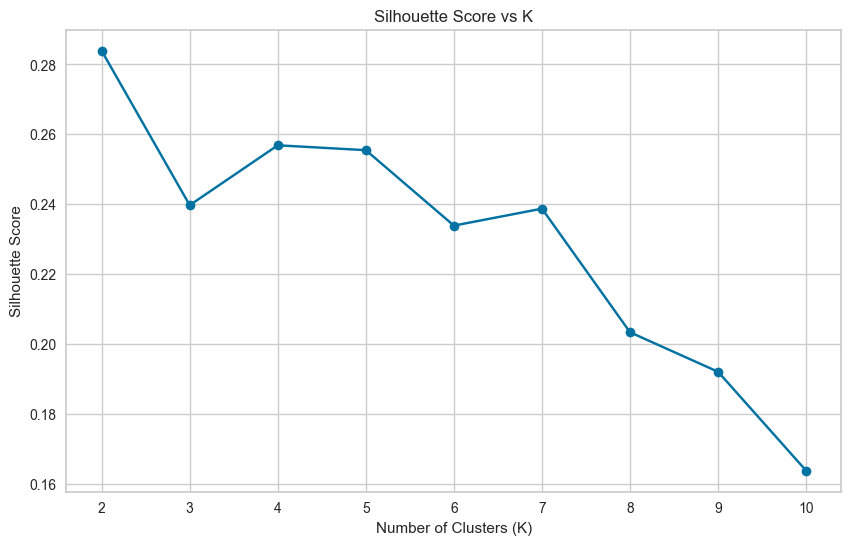

In [37]:
# ============================================
# SILHOUETTE SCORE
# ============================================

plt.figure(figsize=(10, 6))

plt.plot(
    k_results["K"],
    k_results["Silhouette_Score"],
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")

plt.title("Silhouette Score vs K")

plt.xticks(list(k_values))

plt.show()

In [45]:
# ============================================
# HIERARCHICAL CLUSTERING
# ============================================

hierarchical_model = AgglomerativeClustering(n_clusters=7,linkage="ward")

hierarchical_labels = hierarchical_model.fit_predict(X_scaled)

hierarchical_silhouette = silhouette_score(X_scaled,hierarchical_labels)

print("Hierarchical Silhouette Score:",round(hierarchical_silhouette, 4))

Hierarchical Silhouette Score: 0.2311


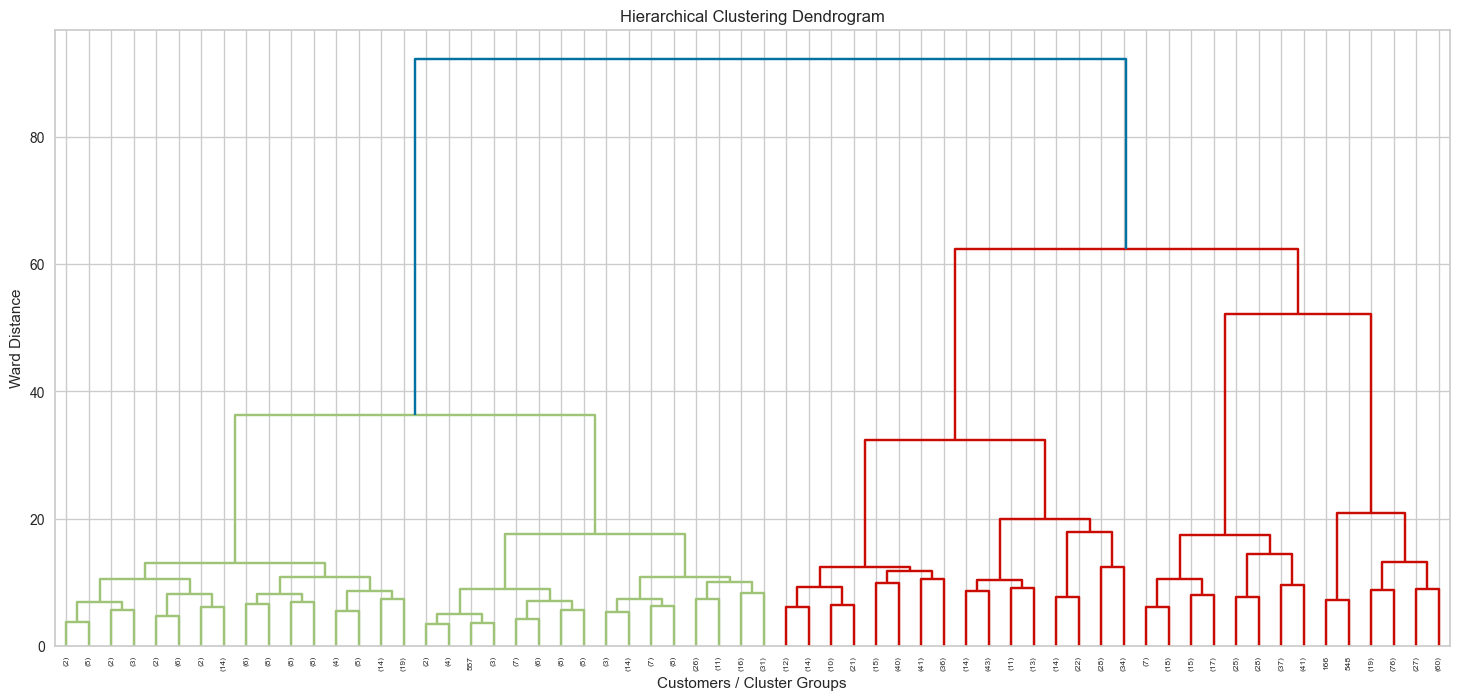

In [46]:
# ============================================
# DENDROGRAM
# ============================================

dendrogram_sample_size = min(1000,len(X_scaled))

dendrogram_sample = X_scaled.sample(n=dendrogram_sample_size,random_state=42)

linkage_matrix = linkage(dendrogram_sample,method="ward")

plt.figure(figsize=(18, 8))

dendrogram(linkage_matrix,truncate_mode="level",p=5)

plt.title("Hierarchical Clustering Dendrogram")

plt.xlabel("Customers / Cluster Groups")
plt.ylabel("Ward Distance")
plt.show()

In [49]:
# ============================================
# FINAL K-MEANS MODEL
# ============================================

final_kmeans = KMeans(n_clusters=7,random_state=42,n_init=20)

final_labels = final_kmeans.fit_predict(X_scaled)

final_silhouette = silhouette_score(X_scaled,final_labels)

print("Final K:", 7)

print("Final Silhouette Score:",round(final_silhouette, 4))

print("Final Inertia:",round(final_kmeans.inertia_, 2))

Final K: 7
Final Silhouette Score: 0.2387
Final Inertia: 65753.71


In [50]:
# ============================================
# ADD CLUSTER LABEL
# ============================================

clustered_customers = df.copy()

clustered_customers["Cluster"] = final_labels

clustered_customers.head()

,Customer_ID,Age,Gender,City_Tier,Annual_Income,Customer_Tenure_Months,Total_Orders,Total_Spending,Average_Order_Value,Website_Visits_Per_Month,Mobile_App_Usage_Rate,Discount_Usage_Rate,Cart_Abandonment_Rate,Return_Rate,Average_Days_Between_Orders,Product_Categories_Purchased,Electronics_Spending,Fashion_Spending,Home_Kitchen_Spending,Beauty_Spending,Customer_Support_Calls,Loyalty_Points,Last_Purchase_Days_Ago,Preferred_Payment_Method,Marketing_Response_Rate,Cluster
0,CUST_00001,18,Male,Tier_3,384000.0,25,2,3900,2100,45,0.83,0.57,0.69,0.08,74.6,3,1800.0,1400.0,300.0,400.0,3,1030,99,UPI,0.34,2
1,CUST_00002,43,Male,Tier_2,NaN,13,7,19300,2600,9,0.50,0.06,0.57,0.07,109.0,1,3200.0,5100.0,5200.0,5900.0,3,757,24,UPI,0.29,1
2,CUST_00003,40,Female,Tier_3,1776000.0,54,62,116400,2000,27,0.82,0.42,0.16,0.00,28.5,3,16400.0,75300.0,8700.0,15900.0,3,12229,124,Credit Card,0.39,0
3,CUST_00004,49,Male,Tier_2,852000.0,10,18,67100,3800,3,0.39,0.51,0.47,0.07,122.5,3,24900.0,19700.0,10700.0,11800.0,1,1454,104,UPI,0.41,1
4,CUST_00005,28,Female,Tier_2,1339000.0,67,48,318700,5750,37,0.79,0.36,0.16,0.03,11.4,6,123700.0,4300.0,154700.0,35900.0,2,8055,15,UPI,0.36,4


In [52]:
# ============================================
# CLUSTER SIZE
# ============================================

cluster_counts = (clustered_customers["Cluster"].value_counts().sort_index())

cluster_summary = pd.DataFrame({"Customer_Count": cluster_counts,"Percentage": (cluster_counts /len(clustered_customers) *100).round(2)})

cluster_summary

,Customer_Count,Percentage
Cluster,,
0,1055,10.55
1,1891,18.91
2,1649,16.49
3,1924,19.24
4,1658,16.58
5,1788,17.88
6,35,0.35


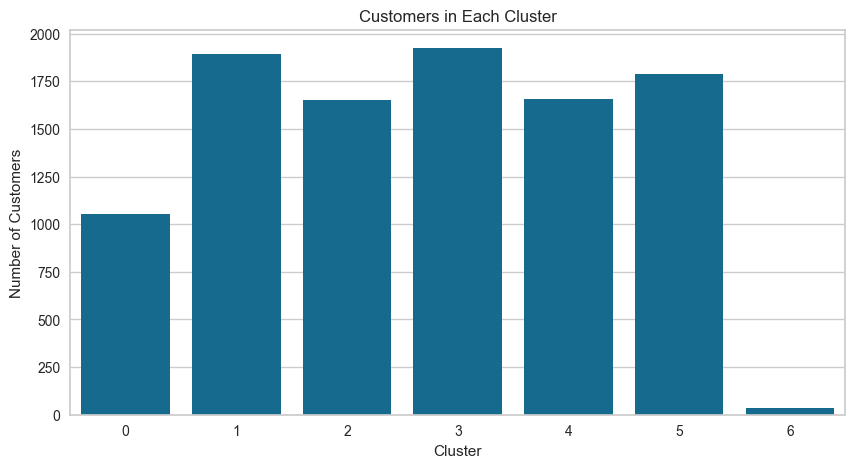

In [53]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=cluster_summary.index,
    y=cluster_summary["Customer_Count"]
)

plt.xlabel("Cluster")
plt.ylabel("Number of Customers")

plt.title("Customers in Each Cluster")

plt.show()

In [54]:
# ============================================
# CREATE DATASET FOR EACH CLUSTER
# ============================================

cluster_datasets = {}

for cluster_id in sorted(
    clustered_customers["Cluster"].unique()):
    cluster_datasets[cluster_id] = (clustered_customers[clustered_customers["Cluster"] == cluster_id].copy())
    print(f"Cluster {cluster_id}:",len(cluster_datasets[cluster_id]),"customers")

Cluster 0: 1055 customers
Cluster 1: 1891 customers
Cluster 2: 1649 customers
Cluster 3: 1924 customers
Cluster 4: 1658 customers
Cluster 5: 1788 customers
Cluster 6: 35 customers


In [56]:
# ============================================
# NUMERICAL CLUSTER PROFILE
# ============================================

cluster_profile = (clustered_customers.groupby("Cluster")[clustering_features].mean().round(2))

cluster_profile.T

Cluster,0,1,2,3,4,5,6
Annual_Income,1292262.96,525921.80,623077.91,691785.71,1504338.63,840022.08,861342.86
Customer_Tenure_Months,58.48,24.67,20.79,29.82,49.08,38.99,38.34
Total_Orders,48.31,5.55,9.24,42.26,55.41,11.84,2.71
Total_Spending,297013.46,9638.45,13779.08,76825.47,361027.93,49729.25,2894.91
Average_Order_Value,6147.01,1708.99,1497.51,1809.77,6524.19,4113.90,1201.14
Website_Visits_Per_Month,11.71,5.18,45.57,24.28,27.66,9.79,336.57
Mobile_App_Usage_Rate,0.64,0.37,0.85,0.71,0.78,0.56,0.61
Discount_Usage_Rate,0.25,0.25,0.54,0.78,0.20,0.31,0.43
Cart_Abandonment_Rate,0.18,0.38,0.72,0.28,0.12,0.24,0.91
Return_Rate,0.08,0.09,0.06,0.10,0.05,0.07,0.07


| Cluster |         Business Persona         | Confidence |                               Main Reason                                        |
|---------|--------------------------------- |------------|----------------------------------------------------------------------------------|
| **0**   | **At-Risk High-Value Customers** | Very High  | Very high spending/orders/income but **195.8 days since purchase**               |
| **1**   | **Occasional Buyers**            | High       | Very low orders, low spending, long purchase gaps                                |
| **2**   | **Window Shoppers**              | Very High  | Very high website visits, high app usage, **72% cart abandonment**, low purchases|
| **3**   | **Discount-Driven Customers**    | Very High  | **78% discount usage**, 70% marketing response, frequent orders                  |
| **4**   | **Premium Loyal Customers**      | Very High  | Highest income/spending/AOV, highest loyalty, frequent purchases                 |
| **5**   | **Occasional / Moderate Buyers** | Medium     | Moderate spending, low order frequency, long purchase gaps                       |
| **6**   | **Low-Engagement Customers**     | Very High  | Only 2.7 orders, lowest spending, extremely high cart abandonment                |